<a href="https://colab.research.google.com/github/AnIsAsPe/LogisticRegression_SpamOpinion/blob/master/Notebooks/Clasificador_resenas_multiclase_Regresion_logistica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/AnIsAsPe/LogisticRegression_SpamOpinion/blob/master/Notebooks/Clasificador_rese%C3%B1as_multiclase_Regresi%C3%B3n_log%C3%ADstica_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cargar Bibliotecas

In [1]:
import numpy as np
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer  ## SnowballStemmer (para español)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, cross_val_predict)
from sklearn.metrics import accuracy_score, RocCurveDisplay

import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

# Funciones

In [4]:
STOPWORDS_RGX = re.compile(r'\b(' + r'|'.join(stopwords.words('english')) + r')\b\s*')

def elimina_stopwords(texto):
  '''
  Quitar todas las palabras palabras vacias (stopwords)
  '''
  nuevo_texto = STOPWORDS_RGX.sub('', texto)
  return nuevo_texto

# https://www.regular-expressions.info/index.html
# https://www.tutorialspoint.com/Why-do-we-use-re-compile-method-in-Python-regular-expression

In [6]:
stopwords.words('english')

['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [7]:
elimina_stopwords("I love how you cook".lower())

'love cook'

**Nota sobre las negaciones.** La lista de stopwords de NLTK incluye negaciones como *no*, *not*, *nor*, *don't* o *wasn't*. Al eliminarlas, *"the room was not clean"* queda como *"room clean"*. Para distinguir reseñas verdaderas de falsas el efecto es pequeño, pero para la **polaridad** (sección 7, regresión multiclase) puede importar.

Una alternativa es quitar las negaciones de la lista antes de construir la expresión regular:

```python
negaciones = {'no', 'not', 'nor'} | {w for w in stopwords.words('english') if w.endswith("n't")}
STOPWORDS_RGX = re.compile(r'\b(' + r'|'.join(w for w in stopwords.words('english')
                                              if w not in negaciones) + r')\b\s*')
```

In [8]:
SOLO_LETRAS_RGX = re.compile(r'[^a-z]+')

def elimina_puntuacion_y_numeros(texto):
  """
  Elimina todo lo que no sea letras minúsculas.
  """
  return SOLO_LETRAS_RGX.sub(' ', texto)

In [9]:
elimina_puntuacion_y_numeros("Is he 8 years old?".lower())

'is he years old '

In [10]:
"Is he 8 years old?".split()

['Is', 'he', '8', 'years', 'old?']

In [11]:
lemma = WordNetLemmatizer()
def lematizar(texto):
  '''
  Lematiza las palabras, enfocandose en los verbos
  '''
  texto = texto.split()
  nuevo_texto = " ".join([lemma.lemmatize(i, 'v') for i in texto])
  return nuevo_texto

# para un mejor funcionamiento necesita saber el tipo de palabra por lo que se
# recomienda usar antes pos_tag

In [ ]:
lematizar("ran run running")

In [12]:
st = PorterStemmer()                  # para inglés
# st = SnowballStemmer("spanish")     # para español

def stemmer(texto):
  texto = texto.split()
  nuevo_texto = ' '.join([st.stem(i) for i in texto])
  return nuevo_texto

In [13]:
stemmer("ran run running")

'ran run run'

In [14]:
def preprocesar(texto):
  texto = texto.lower()
  texto = elimina_stopwords(texto)
  texto = elimina_puntuacion_y_numeros(texto)
  texto = stemmer(texto)
  return(texto)

In [15]:
def matriz_confusion(y_real, y_pred, titulo, ax):
  """
  Dibuja la matriz de confusión en el eje `ax` e incluye la exactitud en el título.
  """
  exactitud = accuracy_score(y_real, y_pred) * 100
  tabla = pd.crosstab(pd.Series(np.asarray(y_real), name='Real'),
                      pd.Series(np.asarray(y_pred), name='Predicción'))
  # Etiquetas en dos renglones (p. ej. 'deceptive\nnegative') para que se lean mejor
  tabla.index = tabla.index.str.replace('-', '\n')
  tabla.columns = tabla.columns.str.replace('-', '\n')
  sns.heatmap(tabla, annot=True, fmt='g', cmap='Blues', cbar=False, ax=ax
              ).set(title='{}, exactitud = {:4.2f}%'.format(titulo, exactitud))
  ax.tick_params(axis='x', labelrotation=0)
  ax.tick_params(axis='y', labelrotation=0)


def evaluacion_cv(modelo, X, y, cv, graph_size=(10, 4)):
  """
  Compara el desempeño en entrenamiento con el de validación cruzada.

  Args:
    modelo: pipeline ya entrenado con (X, y).
    X, y: datos de entrenamiento.
    cv: estrategia de validación cruzada.
    graph_size: tamaño de la figura.

  - Entrenamiento: el modelo predice los mismos datos con los que se ajustó.
  - Validación cruzada: cada reseña se predice con un modelo que NO la vio
    durante su entrenamiento (cross_val_predict).
  """
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=graph_size)
  matriz_confusion(y, modelo.predict(X), 'Entrenamiento', ax1)
  matriz_confusion(y, cross_val_predict(modelo, X, y, cv=cv), 'Validación cruzada', ax2)
  plt.tight_layout()
  plt.show()


def evaluacion_final(modelo, X_train, y_train, X_test, y_test, graph_size=(10, 4)):
  """
  Evalúa el modelo elegido en entrenamiento y en prueba.
  Se usa una sola vez, al final, con el conjunto de prueba.
  """
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=graph_size)
  matriz_confusion(y_train, modelo.predict(X_train), 'Entrenamiento', ax1)
  matriz_confusion(y_test, modelo.predict(X_test), 'Prueba', ax2)
  plt.tight_layout()
  plt.show()

# 1.Lectura de datos

In [16]:
df = pd.read_csv('https://raw.githubusercontent.com/AnIsAsPe/LogisticRegression_SpamOpinion/refs/heads/master/Datos/deceptive-opinion.csv',
                     usecols=['deceptive','polarity', 'text']
                    )
display(df.shape, df.head())

(1600, 3)

,deceptive,polarity,text
0,truthful,positive,We stayed for a one night getaway with family ...
1,truthful,positive,Triple A rate with upgrade to view room was le...
2,truthful,positive,This comes a little late as I'm finally catchi...
3,truthful,positive,The Omni Chicago really delivers on all fronts...
4,truthful,positive,I asked for a high floor away from the elevato...


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   deceptive  1600 non-null   object
 1   polarity   1600 non-null   object
 2   text       1600 non-null   object
dtypes: object(3)
memory usage: 37.6+ KB


In [18]:
pd.crosstab(df['deceptive'], df['polarity'])

polarity,negative,positive
deceptive,,
deceptive,400,400
truthful,400,400


# 2.División inicial Entrenamiento/Prueba
En el ejercicio anterior apartamos un conjunto de **validación** fijo para elegir hiperparámetros. Ahora lo reemplazamos por **validación cruzada** dentro del conjunto de entrenamiento: aprovechamos todos los datos de entrenamiento y obtenemos una estimación más estable.

| Conjunto | % | Para qué se usa |
|---|---|---|
| **Entrenamiento** | 80% | Explorar, preprocesar y elegir hiperparámetros, modelo y umbral **con validación cruzada** |
| **Prueba** | 20% | Estimar el desempeño de los modelos elegidos. **Se usa una sola vez, al final** |

Estratificamos por veracidad y polaridad para que ambos conjuntos conserven las cuatro combinaciones en la misma proporción.

In [19]:
df_train, df_test = train_test_split(df,
                                     test_size=0.20,
                                     shuffle=True,
                                     random_state=8,
                                     stratify=df[['deceptive','polarity']])

print("Registros en Train:", len(df_train))
print("Registros en Test:", len(df_test))

Registros en Train: 1280
Registros en Test: 320


# 3.Exploración y preprocesamiento (entrenamiento)

In [20]:
display(
     df_train['polarity'].value_counts(),
     df_train['deceptive'].value_counts()
)

,count
polarity,
negative,640
positive,640


,count
deceptive,
truthful,640
deceptive,640


In [21]:
df_train['text']

,text
1186,Stayed in old tower. Room was nice and room se...
251,Excellent service! Clean and spacious rooms wi...
1426,My husband and I stayed here at the Hard Rock ...
740,This was my first time in Chicago and I tell y...
1431,I recently stayed at the Hard Rock Hotel in Ch...
...,...
350,Spent a wonderful night at the Amalfi with fri...
1521,My daughter wanted to spend the weekend in Chi...
1468,When I made my reservations at Softiel in Chic...
158,everything that i read from other reviews was ...


In [22]:
df_train['long_text'] = df_train['text'].str.split().str.len()
df_train

,deceptive,polarity,text,long_text
1186,truthful,negative,Stayed in old tower. Room was nice and room se...,138
251,truthful,positive,Excellent service! Clean and spacious rooms wi...,37
1426,deceptive,negative,My husband and I stayed here at the Hard Rock ...,81
740,deceptive,positive,This was my first time in Chicago and I tell y...,104
1431,deceptive,negative,I recently stayed at the Hard Rock Hotel in Ch...,49
...,...,...,...,...
350,truthful,positive,Spent a wonderful night at the Amalfi with fri...,38
1521,deceptive,negative,My daughter wanted to spend the weekend in Chi...,206
1468,deceptive,negative,When I made my reservations at Softiel in Chic...,221
158,truthful,positive,everything that i read from other reviews was ...,172


In [23]:
df_train['long_text'].describe()

,long_text
count,1280.000000
mean,148.719531
std,88.118897
min,25.000000
25%,87.750000
50%,128.500000
75%,183.000000
max,784.000000


## Preprocesamiento de texto

In [24]:
indice = 1473
ejemplo = df_train.loc[indice, 'text']
ejemplo

"For a hotel rated with four diamonds by AAA, one would think the Hilton Chicago would be almost like staying at a palace with royalty. The only royal thing about this hotel however is that it was a royal nightmare. I should have known from the moment I walked in with my wife that this was going to become a bigger headache than what it was worth. First off, as soon as we arrived to check in at the hotel with the clerk who couldn't be any older than nineteen or twenty, red flags started going up. The clerk was extremely rude and lazy, acting like it was a chore even getting up from texting on his cell phone. If that wasn't bad enough, the clerk pretty much ignored me while blatantly staring at my wife's breasts. She wasn't even wearing anything that could be considered skimpy as it was cold out and she was wearing a turtle neck sweater under a large fur lined coat. After diverting his atention several times we finally got our room keys. It shouldn't have been any surprise when we learne

<h3> Transformar texto a minúsculas

In [25]:
ejemplo = ejemplo.lower()
ejemplo

"for a hotel rated with four diamonds by aaa, one would think the hilton chicago would be almost like staying at a palace with royalty. the only royal thing about this hotel however is that it was a royal nightmare. i should have known from the moment i walked in with my wife that this was going to become a bigger headache than what it was worth. first off, as soon as we arrived to check in at the hotel with the clerk who couldn't be any older than nineteen or twenty, red flags started going up. the clerk was extremely rude and lazy, acting like it was a chore even getting up from texting on his cell phone. if that wasn't bad enough, the clerk pretty much ignored me while blatantly staring at my wife's breasts. she wasn't even wearing anything that could be considered skimpy as it was cold out and she was wearing a turtle neck sweater under a large fur lined coat. after diverting his atention several times we finally got our room keys. it shouldn't have been any surprise when we learne

<h3> Quitar puntuación

In [26]:
ejemplo = elimina_puntuacion_y_numeros(ejemplo)
ejemplo

'for a hotel rated with four diamonds by aaa one would think the hilton chicago would be almost like staying at a palace with royalty the only royal thing about this hotel however is that it was a royal nightmare i should have known from the moment i walked in with my wife that this was going to become a bigger headache than what it was worth first off as soon as we arrived to check in at the hotel with the clerk who couldn t be any older than nineteen or twenty red flags started going up the clerk was extremely rude and lazy acting like it was a chore even getting up from texting on his cell phone if that wasn t bad enough the clerk pretty much ignored me while blatantly staring at my wife s breasts she wasn t even wearing anything that could be considered skimpy as it was cold out and she was wearing a turtle neck sweater under a large fur lined coat after diverting his atention several times we finally got our room keys it shouldn t have been any surprise when we learned that there 

<h3> Quitar Palabras Irrelevantes ("Stopwords")

In [27]:
ejemplo = elimina_stopwords(ejemplo)
ejemplo

'hotel rated four diamonds aaa one would think hilton chicago would almost like staying palace royalty royal thing hotel however royal nightmare known moment walked wife going become bigger headache worth first soon arrived check hotel clerk older nineteen twenty red flags started going clerk extremely rude lazy acting like chore even getting texting cell phone bad enough clerk pretty much ignored blatantly staring wife breasts even wearing anything could considered skimpy cold wearing turtle neck sweater large fur lined coat diverting atention several times finally got room keys surprise learned no one help us luggage clerk said break okay annoying managed easy enough finally got third floor suite reserved month looked forward resting long trip surprise not mention disgust horror already couple supposed room bed making took almost half hour couple room front desk wife get straightened apparently night clerk bother following policy taken reservation computer give friends leaving printe

<h3> Normalización
Existen dos principales técnicas para normalizar el texto, la lematización y "radicalización" o stemming, que consiste en la  conversión de palabras en las raices

Referencia:

https://towardsdatascience.com/introduction-to-nlp-part-2-difference-between-lemmatisation-and-stemming-3789be1c55bc

In [28]:
ejemplo_lema = lematizar(ejemplo)
ejemplo_lema

'hotel rat four diamonds aaa one would think hilton chicago would almost like stay palace royalty royal thing hotel however royal nightmare know moment walk wife go become bigger headache worth first soon arrive check hotel clerk older nineteen twenty red flag start go clerk extremely rude lazy act like chore even get texting cell phone bad enough clerk pretty much ignore blatantly star wife breast even wear anything could consider skimpy cold wear turtle neck sweater large fur line coat divert atention several time finally get room key surprise learn no one help us luggage clerk say break okay annoy manage easy enough finally get third floor suite reserve month look forward rest long trip surprise not mention disgust horror already couple suppose room bed make take almost half hour couple room front desk wife get straighten apparently night clerk bother follow policy take reservation computer give friends leave print card day clerk could describe chaos finally give another room next f

In [29]:
ejemplo_stem = stemmer(ejemplo)
ejemplo_stem

'hotel rate four diamond aaa one would think hilton chicago would almost like stay palac royalti royal thing hotel howev royal nightmar known moment walk wife go becom bigger headach worth first soon arriv check hotel clerk older nineteen twenti red flag start go clerk extrem rude lazi act like chore even get text cell phone bad enough clerk pretti much ignor blatantli stare wife breast even wear anyth could consid skimpi cold wear turtl neck sweater larg fur line coat divert atent sever time final got room key surpris learn no one help us luggag clerk said break okay annoy manag easi enough final got third floor suit reserv month look forward rest long trip surpris not mention disgust horror alreadi coupl suppos room bed make took almost half hour coupl room front desk wife get straighten appar night clerk bother follow polici taken reserv comput give friend leav print card day clerk could describ chao final given anoth room next floor thank got wife went use bathroom drop luggag bed 

<h3> Todo junto

In [30]:
df_train['text_pp'] = df_train['text'].apply(preprocesar)
df_train['long_text_pp'] = df_train['text_pp'].str.split().str.len()
df_train.head()

,deceptive,polarity,text,long_text,text_pp,long_text_pp
1186,truthful,negative,Stayed in old tower. Room was nice and room se...,138,stay old tower room nice room servic good room...,73
251,truthful,positive,Excellent service! Clean and spacious rooms wi...,37,excel servic clean spaciou room great view dow...,23
1426,deceptive,negative,My husband and I stayed here at the Hard Rock ...,81,husband stay hard rock hotel chicago month bac...,33
740,deceptive,positive,This was my first time in Chicago and I tell y...,104,first time chicago tell realli made feel like ...,45
1431,deceptive,negative,I recently stayed at the Hard Rock Hotel in Ch...,49,recent stay hard rock hotel chicago il start e...,24


## Visualización de nubes de palabras

In [31]:
def nube_palabras(sec_textos):
    # Crear la cadena con la que haremos la nube de palabras
    text= " ".join(review for review in sec_textos)

    # Crear la nube de palabras
    wordcloud = WordCloud( max_font_size=50,
                          max_words=100,
                          background_color="white").generate(text)

    # Desplegar la imagen generada
    plt.figure(figsize=[10,12])
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.show()

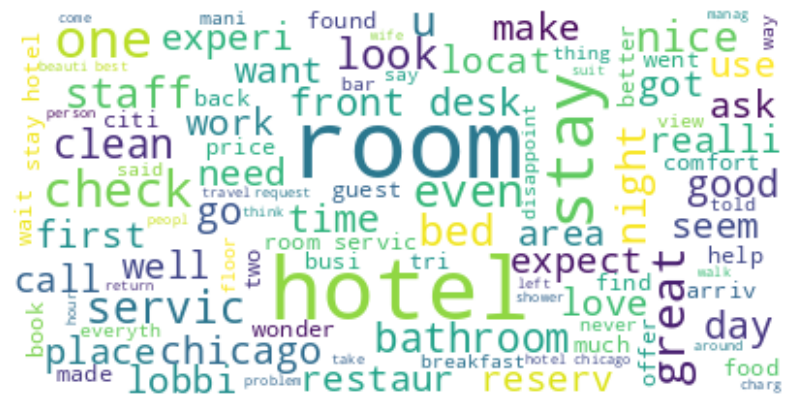

In [32]:
nube_palabras(df_train['text_pp'])

In [33]:
porClase = df_train.groupby('deceptive')
verdaderas = porClase.get_group('truthful').text_pp
falsas = porClase.get_group('deceptive').text_pp

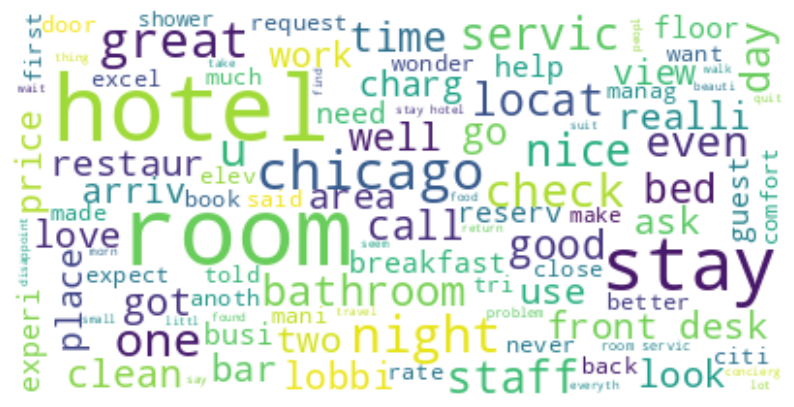

In [34]:
nube_palabras(verdaderas)

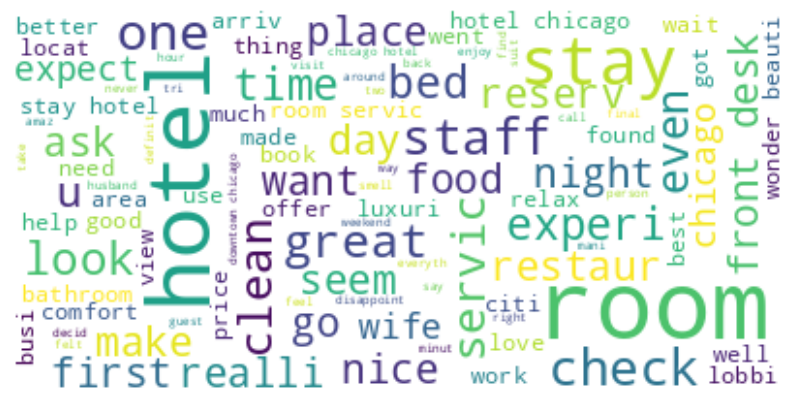

In [35]:
nube_palabras(falsas)

## Vectorización de Texto mediante BOW

In [36]:
vectorizer = TfidfVectorizer(min_df=2)
X_train_tfidf = vectorizer.fit_transform(df_train['text_pp'])
X_train_tfidf.shape

(1280, 3281)

In [37]:
X_train_tfidf

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 74460 stored elements and shape (1280, 3281)>

In [38]:
# Solo para visualizar la estructura: 1 renglón por reseña y 1 columna por token.
# No lo guardamos en una variable: el modelo trabaja directamente con la matriz dispersa,
# que solo almacena los valores distintos de cero y es mucho más rápida.
pd.DataFrame(X_train_tfidf.toarray(),
             index=df_train.index,
             columns=vectorizer.get_feature_names_out())

,aaa,abil,abl,abrupt,absent,absolut,absurd,abund,abysm,ac,...,yogurt,york,young,younger,yuck,yummi,yup,zest,zone,zoo
1186,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
251,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1426,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
740,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1431,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
350,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1521,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1468,0.0,0.0,0.0,0.15633,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
158,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Vectorización y modelo en un Pipeline
El vectorizador TF-IDF **aprende de los datos**: el vocabulario (con `min_df=2` solo conserva palabras que aparecen en al menos 2 reseñas) y el peso IDF de cada palabra. Si lo ajustamos con todo el entrenamiento antes de la validación cruzada, la información de los folds de validación se filtra al modelo (*data leakage*).

Por eso lo integramos con el modelo en un **Pipeline**: en cada fold, TF-IDF se ajusta solo con los datos de entrenamiento de ese fold. El vectorizador de la celda anterior fue solo para explorar.

En cambio, la función `preprocesar` (minúsculas, stopwords, stemming) trabaja reseña por reseña y **no aprende nada** de los datos, así que puede aplicarse fuera del Pipeline.

Sobre la penalización:
* `C` es el inverso de la fuerza de la regularización: $C = 1/\lambda$.
* `C=np.inf` equivale a **no penalizar** ($\lambda = 0$).
* Cualquier otro valor de `C` aplica la penalización por defecto, **L2 (Ridge)**.


In [54]:
def crear_pipeline(C=1.0):
    """TF-IDF + regresión logística. C = 1/λ; C=np.inf equivale a no penalizar."""
    return Pipeline([
        ('tfidf', TfidfVectorizer(min_df=2)),
        ('modelo', LogisticRegression(C=C,
                                      solver='sag',
                                      max_iter=1500,   # Default 100
                                      tol=0.0001,      # Default 1e-4
                                      random_state=4)),
    ])

In [42]:
X_train = df_train['text_pp']     # el Pipeline recibe el texto preprocesado
y_train = df_train['deceptive']

# 4.Preprocesamiento de texto del conjunto de prueba
Aplicamos la misma limpieza de texto. Es seguro hacerlo porque `preprocesar` no aprende nada de los datos; la vectorización la hará el Pipeline con lo aprendido en entrenamiento.

In [43]:
df_test['text_pp'] = df_test['text'].apply(preprocesar)

X_test = df_test['text_pp']
y_test = df_test['deceptive']

# 5.Regresión Logística sin penalización

In [44]:
clasificador_rl = crear_pipeline(C=np.inf).fit(X_train, y_train)

## Validación cruzada
Para evaluar el modelo sin tocar el conjunto de prueba, dividimos el entrenamiento en $k=5$ partes (*folds*). Entrenamos 5 veces: cada vez validamos con un fold distinto y entrenamos con los otros 4. Así, cada reseña se usa exactamente una vez para validar.

Usamos `StratifiedKFold` para que cada fold conserve la proporción de clases.

In [45]:
k = 5
cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

val_index_dic = {}
train_index_dic = {}
for i, (train_index, val_index) in enumerate(cv.split(X_train, y_train)):
    train_index_dic[i] = train_index
    val_index_dic[i] = val_index
    print(f'Fold {i}: {len(train_index)} reseñas para entrenar, {len(val_index)} para validar | '
          f'proporción de "deceptive" en validación: {(y_train.iloc[val_index] == "deceptive").mean():.2f}')

Fold 0: 1024 reseñas para entrenar, 256 para validar | proporción de "deceptive" en validación: 0.50
Fold 1: 1024 reseñas para entrenar, 256 para validar | proporción de "deceptive" en validación: 0.50
Fold 2: 1024 reseñas para entrenar, 256 para validar | proporción de "deceptive" en validación: 0.50
Fold 3: 1024 reseñas para entrenar, 256 para validar | proporción de "deceptive" en validación: 0.50
Fold 4: 1024 reseñas para entrenar, 256 para validar | proporción de "deceptive" en validación: 0.50


In [46]:
i = 1
display(len(val_index_dic[i]), val_index_dic[i])
display(len(train_index_dic[i]), train_index_dic[i])

256

array([   3,    6,    9,   10,   11,   13,   14,   20,   24,   28,   31,
         32,   39,   44,   46,   68,   74,   76,   81,   83,  102,  104,
        107,  113,  116,  127,  141,  143,  145,  147,  152,  156,  169,
        173,  174,  179,  181,  184,  189,  190,  192,  201,  203,  209,
        211,  215,  221,  231,  248,  249,  251,  257,  263,  264,  283,
        284,  289,  290,  291,  292,  295,  297,  310,  312,  313,  321,
        329,  331,  332,  334,  340,  341,  343,  346,  347,  349,  368,
        371,  377,  378,  379,  384,  392,  393,  402,  412,  418,  419,
        422,  424,  425,  426,  435,  436,  441,  442,  449,  451,  456,
        462,  476,  484,  488,  492,  499,  502,  514,  519,  524,  526,
        532,  534,  552,  558,  566,  567,  568,  575,  578,  588,  589,
        593,  595,  600,  601,  602,  612,  616,  623,  632,  645,  658,
        661,  664,  674,  681,  683,  691,  693,  694,  696,  700,  701,
        706,  708,  715,  717,  722,  726,  730,  7

1024

array([   0,    1,    2, ..., 1276, 1278, 1279], shape=(1024,))

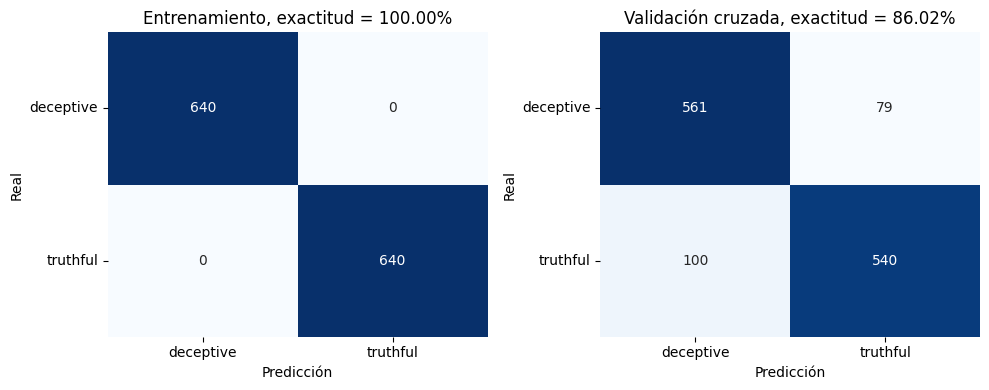

In [47]:
evaluacion_cv(clasificador_rl, X_train, y_train, cv)

# 6.Regresión Logística con penalización Ridge

## ¿De qué magnitud debe ser la fuerza de la regularización (λ)? (Búsqueda de hiperparámetros)
`GridSearchCV` prueba cada valor de λ con validación cruzada y se queda con el de mayor exactitud promedio.

Con un Pipeline, los hiperparámetros se nombran con el nombre del paso, dos guiones bajos y el nombre del parámetro: `modelo__C`.

In [48]:
%%time
lambdas = np.logspace(-3, 3, 25)     # fuerza de la regularización λ, de 0.001 a 1000

grid_search = GridSearchCV(estimator=crear_pipeline(),            # C se asignará en la búsqueda
                           param_grid={'modelo__C': 1/lambdas},   # C = 1/λ
                           cv=cv,
                           return_train_score=True,
                           n_jobs=-1                              # usa todos los núcleos disponibles
                           ).fit(X_train, y_train)

CPU times: user 1.03 s, sys: 59 ms, total: 1.08 s
Wall time: 39.1 s


In [49]:
pd.DataFrame(grid_search.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_modelo__C,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,...,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
0,1.149620,0.133274,0.030560,0.002590,1000.000000,{'modelo__C': 1000.0},0.871094,0.898438,0.824219,0.859375,...,0.860156,0.024631,3,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
1,0.948728,0.099603,0.031304,0.001911,562.341325,{'modelo__C': 562.3413251903492},0.871094,0.902344,0.820312,0.855469,...,0.860156,0.026769,3,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
2,0.812828,0.045063,0.038582,0.014637,316.227766,{'modelo__C': 316.2277660168379},0.871094,0.902344,0.816406,0.855469,...,0.860156,0.027776,3,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
3,0.687138,0.072783,0.032697,0.003132,177.827941,{'modelo__C': 177.82794100389228},0.871094,0.906250,0.828125,0.851562,...,0.861719,0.026099,1,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
4,1.059347,0.212220,0.048948,0.015110,100.000000,{'modelo__C': 100.0},0.867188,0.906250,0.820312,0.855469,...,0.860938,0.027577,2,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
5,0.639167,0.166102,0.032051,0.002482,56.234133,{'modelo__C': 56.2341325190349},0.867188,0.910156,0.820312,0.855469,...,0.859375,0.029749,6,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
6,0.418184,0.012046,0.032442,0.002770,31.622777,{'modelo__C': 31.622776601683796},0.863281,0.906250,0.820312,0.847656,...,0.855469,0.028917,10,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
7,0.336562,0.010832,0.032963,0.001553,17.782794,{'modelo__C': 17.78279410038923},0.867188,0.910156,0.828125,0.847656,...,0.858594,0.028747,8,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
8,0.272838,0.012103,0.030612,0.000983,10.000000,{'modelo__C': 10.0},0.878906,0.906250,0.824219,0.851562,...,0.859375,0.029749,6,0.999023,0.999023,0.999023,1.000000,0.999023,0.999219,0.000391
9,0.225776,0.002884,0.030853,0.001174,5.623413,{'modelo__C': 5.62341325190349},0.882812,0.902344,0.824219,0.855469,...,0.858594,0.030399,8,0.996094,0.997070,0.997070,0.998047,0.996094,0.996875,0.000731


In [50]:
cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results['lambda'] = 1 / cv_results['param_modelo__C']
cv_results[['lambda', 'param_modelo__C', 'mean_train_score', 'mean_test_score', 'std_test_score']]

,lambda,param_modelo__C,mean_train_score,mean_test_score,std_test_score
0,0.001000,1000.000000,1.000000,0.860156,0.024631
1,0.001778,562.341325,1.000000,0.860156,0.026769
2,0.003162,316.227766,1.000000,0.860156,0.027776
3,0.005623,177.827941,1.000000,0.861719,0.026099
4,0.010000,100.000000,1.000000,0.860938,0.027577
5,0.017783,56.234133,1.000000,0.859375,0.029749
6,0.031623,31.622777,1.000000,0.855469,0.028917
7,0.056234,17.782794,1.000000,0.858594,0.028747
8,0.100000,10.000000,0.999219,0.859375,0.029749
9,0.177828,5.623413,0.996875,0.858594,0.030399


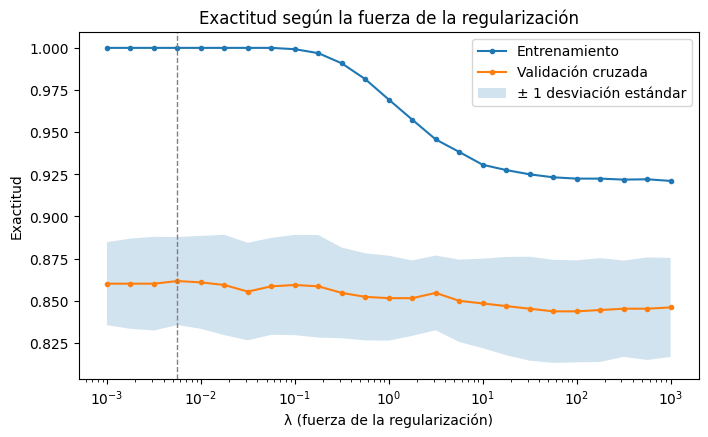

In [51]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(cv_results['lambda'], cv_results['mean_train_score'], marker='.', label='Entrenamiento')
ax.plot(cv_results['lambda'], cv_results['mean_test_score'], marker='.', label='Validación cruzada')
ax.fill_between(cv_results['lambda'],
                cv_results['mean_test_score'] - cv_results['std_test_score'],
                cv_results['mean_test_score'] + cv_results['std_test_score'],
                alpha=0.2, label='± 1 desviación estándar')
ax.axvline(1 / grid_search.best_params_['modelo__C'], color='gray', ls='--', lw=1)
ax.set(xscale='log', xlabel='λ (fuerza de la regularización)', ylabel='Exactitud',
       title='Exactitud según la fuerza de la regularización')
ax.legend()
plt.show()

* Con λ grande el modelo se simplifica demasiado y baja la exactitud en ambos conjuntos (**subajuste**).
* Con λ pequeño la exactitud en entrenamiento llega a 100% (**sobreajuste**), pero la de validación cruzada casi no cambia.
* En una zona amplia de λ las diferencias son menores que la desviación estándar entre folds: varios valores son prácticamente equivalentes.

In [52]:
C_best = grid_search.best_params_['modelo__C']

In [53]:
C_best

np.float64(177.82794100389228)

Reentrenamos con **todo** el conjunto de entrenamiento usando el mejor `C`. Como usamos la misma función `crear_pipeline`, la configuración es exactamente la de la búsqueda.

In [55]:
clasificador_ridge = crear_pipeline(C=C_best).fit(X_train, y_train)
clasificador_ridge

Pipeline(steps=[('tfidf', TfidfVectorizer(min_df=2)),
                ('modelo',
                 LogisticRegression(C=np.float64(177.82794100389228),
                                    max_iter=1500, random_state=4,
                                    solver='sag'))])

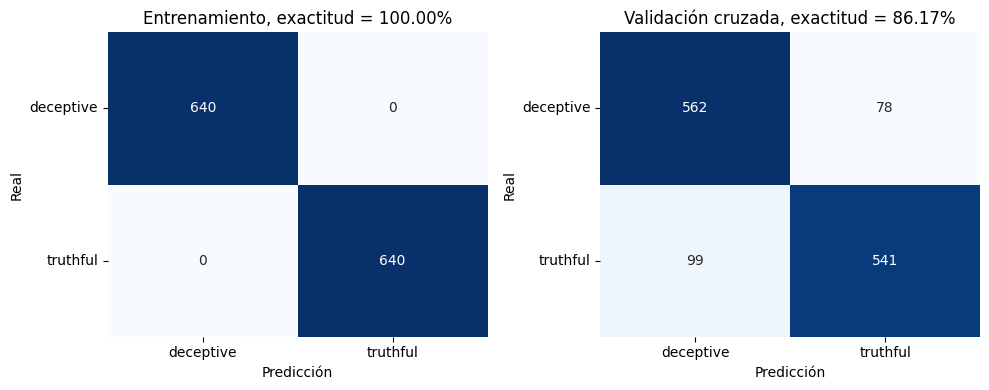

In [56]:
evaluacion_cv(clasificador_ridge, X_train, y_train, cv)

## Predicciones y certeza de la predicción
Para analizar las probabilidades sin usar el conjunto de prueba, usamos probabilidades **fuera de fold** (`cross_val_predict`): cada reseña de entrenamiento se predice con un modelo que no la vio.

In [57]:
clasificador_ridge.classes_

array(['deceptive', 'truthful'], dtype=object)

In [58]:
proba_cv = cross_val_predict(crear_pipeline(C=C_best), X_train, y_train,
                             cv=cv, method='predict_proba')
proba_cv[:10]

array([[1.70188376e-01, 8.29811624e-01],
       [2.06583560e-02, 9.79341644e-01],
       [9.97326529e-01, 2.67347102e-03],
       [9.98844893e-01, 1.15510724e-03],
       [9.93573270e-01, 6.42673003e-03],
       [3.13610230e-04, 9.99686390e-01],
       [9.95915435e-01, 4.08456546e-03],
       [6.11911648e-02, 9.38808835e-01],
       [2.69074672e-01, 7.30925328e-01],
       [9.65325889e-01, 3.46741109e-02]])

In [59]:
# Las columnas siguen el orden de classes_: ['deceptive', 'truthful']
predicciones = pd.DataFrame({'P(deceptive)': proba_cv[:, 0],
                             'P(truthful)':  proba_cv[:, 1],
                             'y_real':       y_train},
                            index=y_train.index)
predicciones['y_pred_50'] = np.where(predicciones['P(deceptive)'] > 0.5, 'deceptive', 'truthful')

# Reseñas alrededor de P(deceptive) = 0.5, donde el modelo tiene menos certeza
predicciones.sort_values('P(deceptive)', ascending=False).iloc[620:660]

,P(deceptive),P(truthful),y_real,y_pred_50
13,0.610432,0.389568,truthful,deceptive
268,0.609719,0.390281,truthful,deceptive
612,0.608036,0.391964,deceptive,deceptive
1402,0.604208,0.395792,deceptive,deceptive
1346,0.603503,0.396497,deceptive,deceptive
1092,0.599423,0.400577,truthful,deceptive
487,0.596231,0.403769,deceptive,deceptive
937,0.585830,0.414170,truthful,deceptive
39,0.584709,0.415291,truthful,deceptive
768,0.579631,0.420369,deceptive,deceptive


## ¿Qué umbral usar?
El umbral depende del **contexto**. Supongamos que una plataforma usará el modelo para **marcar reseñas sospechosas de ser falsas**:
* Si para la plataforma es más grave **dejar pasar una reseña falsa**, conviene **bajar** el umbral de `P(deceptive)`: marcamos más reseñas como falsas, aunque algunas verdaderas queden marcadas por error.
* Si es más grave **marcar como falsa una reseña verdadera** (por ejemplo, porque se elimina automáticamente y afecta a clientes reales), conviene un umbral **más alto**.

Como ejemplo, probamos un umbral de 0.3 y lo comparamos con 0.5 usando las predicciones fuera de fold.

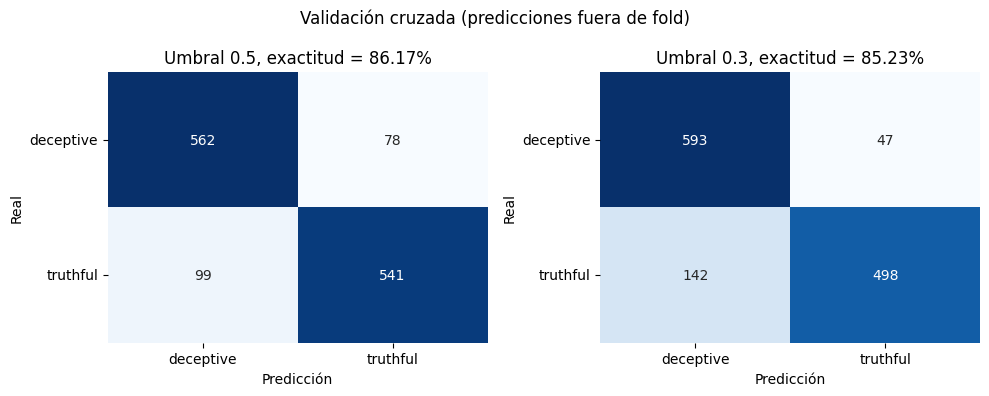

In [60]:
umbral = 0.3
predicciones['y_pred_30'] = np.where(predicciones['P(deceptive)'] > umbral, 'deceptive', 'truthful')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
matriz_confusion(predicciones['y_real'], predicciones['y_pred_50'], 'Umbral 0.5', ax1)
matriz_confusion(predicciones['y_real'], predicciones['y_pred_30'], f'Umbral {umbral}', ax2)
plt.suptitle('Validación cruzada (predicciones fuera de fold)')
plt.tight_layout()
plt.show()

## Curvas ROC y Precision-Recall
Área bajo la curva entre:

- True Positive Rate (Sensitivity): Verdaderos Positivos / Positivos

- False Positive Rate (1-Specificity): Falsos Positivos / Negativos

Junto a ella graficamos la curva **Precision-Recall**: precision (de las reseñas marcadas como falsas, cuántas lo son) contra recall (de las reseñas falsas, cuántas detectamos). Su área se resume con el **AP** (*average precision*); un modelo al azar obtiene un AP igual a la proporción de reseñas falsas (0.5 en este dataset).

Comparamos ambos modelos con probabilidades fuera de fold. Tomamos como clase positiva `deceptive`, la que nos interesa detectar.

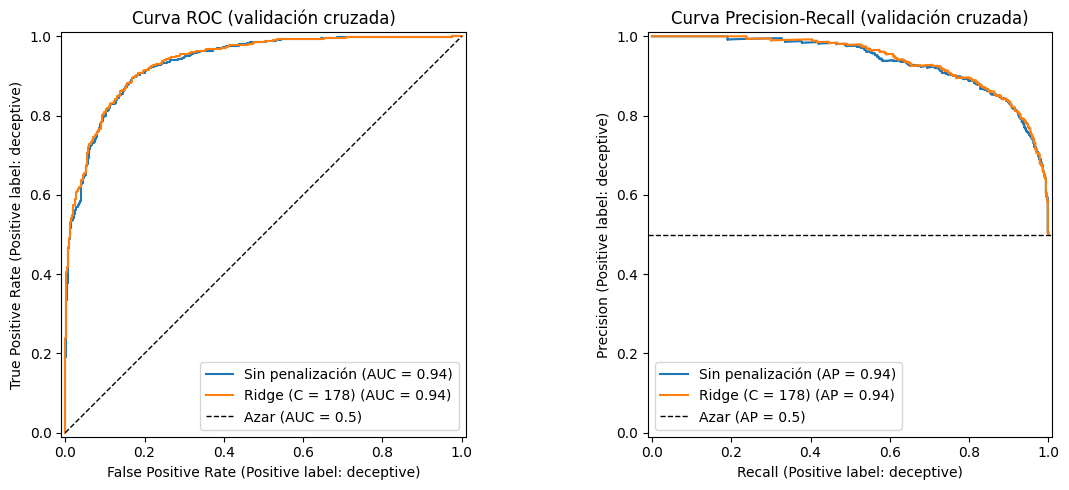

In [85]:

from sklearn.metrics import accuracy_score, RocCurveDisplay, PrecisionRecallDisplay
proba_cv_rl = cross_val_predict(crear_pipeline(C=np.inf), X_train, y_train,
                                cv=cv, method='predict_proba')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

for nombre, proba in [('Sin penalización', proba_cv_rl), (f'Ridge (C = {C_best:.3g})', proba_cv)]:
    RocCurveDisplay.from_predictions(y_train, proba[:, 0], pos_label='deceptive',
                                     name=nombre, ax=ax1)
    PrecisionRecallDisplay.from_predictions(y_train, proba[:, 0], pos_label='deceptive',
                                            name=nombre, ax=ax2)

ax1.plot([0, 1], [0, 1], 'k--', lw=1, label='Azar (AUC = 0.5)')
ax2.axhline((y_train == 'deceptive').mean(), color='k', ls='--', lw=1, label='Azar (AP = 0.5)')
ax1.set_title('Curva ROC (validación cruzada)')
ax2.set_title('Curva Precision-Recall (validación cruzada)')
ax1.legend(loc='lower right')
ax2.legend(loc='lower left')
plt.tight_layout()
plt.show()

## ¿Para qué sirve entonces Ridge?: Da probabilidades más honestas.
Ambos modelos ordenan casi igual las reseñas (mismo AUC), pero no asignan las mismas probabilidades.

Comparamos la distribución de `P(deceptive)` fuera de fold.

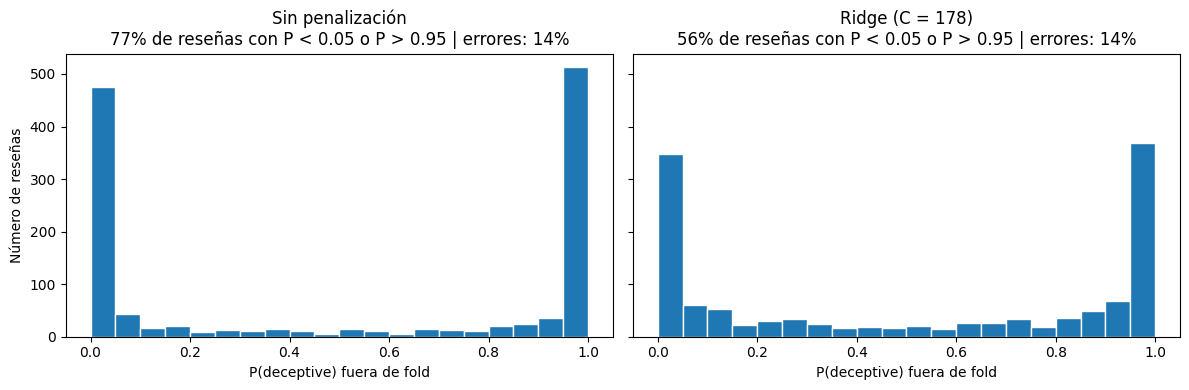

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, (nombre, proba) in zip(axes, [('Sin penalización', proba_cv_rl),
                                      (f'Ridge (C = {C_best:.3g})', proba_cv)]):
    p = proba[:, 0]                                            # P(deceptive)
    extremos = np.mean((p < 0.05) | (p > 0.95)) * 100
    errores = np.mean(np.where(p > 0.5, 'deceptive', 'truthful') != y_train) * 100
    ax.hist(p, bins=20, range=(0, 1), edgecolor='white')
    ax.set(title=f'{nombre}\n{extremos:.0f}% de reseñas con P < 0.05 o P > 0.95 | errores: {errores:.0f}%',
           xlabel='P(deceptive) fuera de fold')

axes[0].set_ylabel('Número de reseñas')
plt.tight_layout()
plt.show()

Para cada reseña, la **seguridad** del modelo es la probabilidad de la clase que predice. Revisamos las reseñas que cada modelo clasificó **mal**: ¿se equivocó dudando o se equivocó muy seguro?

In [69]:
resumen = {}
for nombre, proba in [('Sin penalización', proba_cv_rl), (f'Ridge (C = {C_best:.3g})', proba_cv)]:
    seguridad = proba.max(axis=1)                          # probabilidad de la clase predicha
    y_pred = np.where(proba[:, 0] > 0.5, 'deceptive', 'truthful')
    error = y_pred != y_train
    resumen[nombre] = {'Seguridad promedio': seguridad.mean() * 100,
                       'Exactitud real': (1 - error.mean()) * 100,
                       'Errores con más de 90% de seguridad': (seguridad[error] > 0.9).mean() * 100}
resumen = pd.DataFrame(resumen).T


resumen.round(1)

,Seguridad promedio,Exactitud real,Errores con más de 90% de seguridad
Sin penalización,94.7,86.0,55.3
Ridge (C = 178),89.6,86.2,27.1


## Magnitud de los coeficientes para ambos modelos
Como `classes_ = ['deceptive', 'truthful']`, la regresión logística modela la probabilidad de la segunda clase, **truthful**:
* Coeficiente **positivo**: la palabra aumenta la probabilidad de que la reseña sea **verdadera**.
* Coeficiente **negativo**: la palabra aumenta la probabilidad de que la reseña sea **falsa**.

In [62]:
clasificador_rl['modelo'].coef_

array([[-3.17997263,  0.17524699, -0.80045448, ..., -0.36065012,
         3.52759804,  0.32596851]], shape=(1, 3281))

In [63]:
# Observa las magnitudes de los coeficientes del modelo
# sin y con regularización Ridge

coef_rl = pd.Series(
    clasificador_rl['modelo'].coef_[0],
    index=clasificador_rl['tfidf'].get_feature_names_out(),
    name='SinRegularizacion'
    )
coef_ridge = pd.Series(
    clasificador_ridge['modelo'].coef_[0],
    index=clasificador_ridge['tfidf'].get_feature_names_out(),
    name='Ridge'
    )
coef = pd.concat([coef_rl, coef_ridge], axis=1)
coef.sort_values(by='Ridge', ascending=False)

,SinRegularizacion,Ridge
confer,21.845604,10.196560
review,19.665669,9.773122
street,19.460254,9.241586
call,19.849535,9.146153
bathroom,19.851338,9.013286
...,...,...
food,-17.008608,-8.330713
relax,-17.414933,-8.810522
recent,-20.391257,-10.066589
luxuri,-25.639051,-12.769198


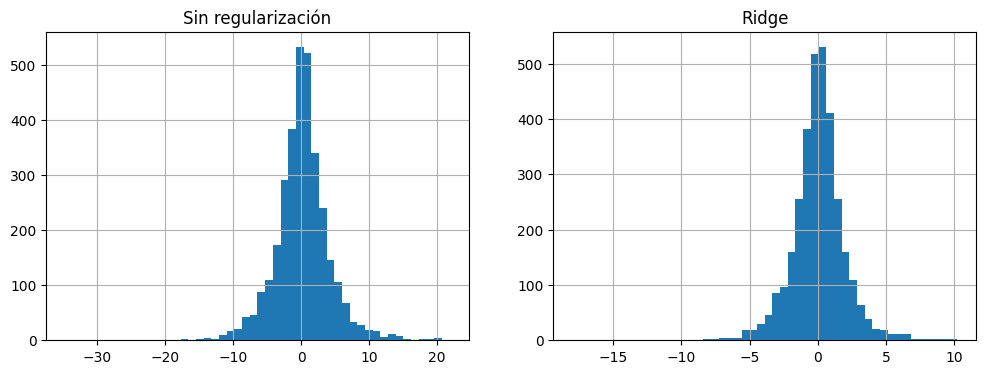

In [64]:
fig, (ax1,ax2) = plt.subplots(1,2, figsize=(12,4))

coef['SinRegularizacion'].hist(ax=ax1, bins=50)
ax1.set_title('Sin regularización')

coef['Ridge'].hist(ax=ax2, bins=50)
ax2.set_title('Ridge')


plt.show()

$e^{\beta}$ es la **razón de momios** (*odds ratio*): cuántas veces se multiplican los momios de que la reseña sea verdadera cuando el TF-IDF de la palabra aumenta en una unidad.

Ojo: un aumento de una unidad en TF-IDF es muy grande (la mayoría de los valores son menores a 0.3), así que estas cifras exageran el efecto real. Sirven sobre todo para **ordenar** las palabras por su influencia.

In [65]:
# Palabras que más aumentan la probabilidad de que la reseña sea VERDADERA (coeficientes positivos)
np.exp(coef).sort_values(by='Ridge', ascending=False).head(15)

,SinRegularizacion,Ridge
confer,3.072030e+09,26810.794158
review,3.472896e+08,17555.496302
street,2.828011e+08,10317.392108
call,4.173915e+08,9378.294521
bathroom,4.181448e+08,8211.455983
pricelin,5.221911e+08,8134.940284
floor,1.274053e+08,7910.900325
breakfast,6.470677e+07,4000.641057
elev,5.837333e+07,3217.376951
block,3.541132e+07,2873.560065


In [66]:
# Palabras que más aumentan la probabilidad de que la reseña sea FALSA (coeficientes negativos).
# e^(-β): cuántas veces se multiplican los momios de que la reseña sea falsa
np.exp(-coef).sort_values(by='Ridge', ascending=False).head(15)

,SinRegularizacion,Ridge
chicago,1.157149e+15,6.410991e+07
luxuri,1.364264e+11,3.512305e+05
recent,7.174809e+08,2.354311e+04
relax,3.657711e+07,6.704418e+03
food,2.436377e+07,4.149376e+03
satisfi,3.520702e+06,2.594194e+03
millennium,1.186632e+07,1.821060e+03
seem,2.372843e+06,1.813150e+03
clean,8.443785e+05,1.035777e+03
final,1.636450e+06,9.624889e+02


## Evaluación final en el conjunto de prueba
Elegimos el modelo con penalización Ridge y el `C` encontrado con validación cruzada. Es la **única vez** que usamos el conjunto de prueba para la clasificación binaria.

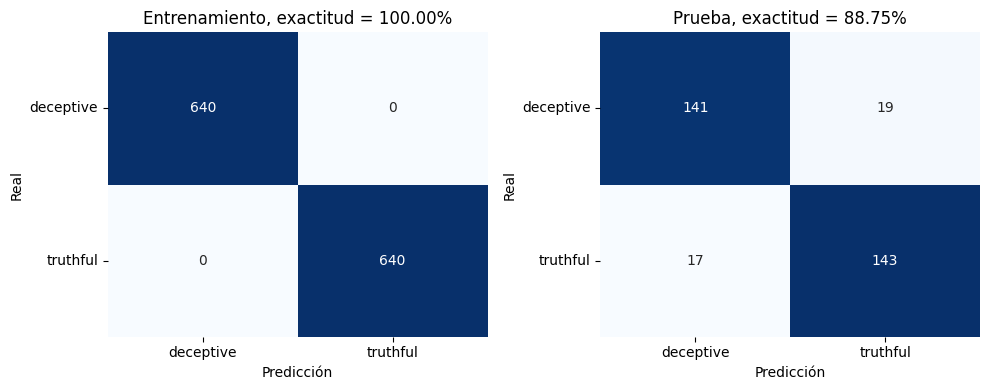

In [70]:
evaluacion_final(clasificador_ridge, X_train, y_train, X_test, y_test)

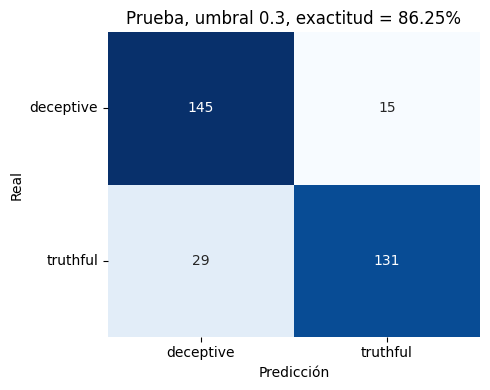

In [72]:
# Con el umbral elegido según el contexto
proba_test = clasificador_ridge.predict_proba(X_test)
y_pred_test_umbral = np.where(proba_test[:, 0] > umbral, 'deceptive', 'truthful')

fig, ax = plt.subplots(figsize=(5, 4))
matriz_confusion(y_test, y_pred_test_umbral, f'Prueba, umbral {umbral}', ax)
plt.tight_layout()
plt.show()

# 7.Regresión Multiclase
Ahora la etiqueta combina veracidad y polaridad (4 clases). Repetimos el flujo: modelo sin penalización evaluado con validación cruzada, búsqueda de λ con `GridSearchCV` y evaluación final en prueba.

In [73]:
y_train_mc = df_train['deceptive'].str.cat(df_train['polarity'], sep='-').rename('clase')
y_test_mc = df_test['deceptive'].str.cat(df_test['polarity'], sep='-').rename('clase')

y_train_mc.value_counts()

,count
clase,
truthful-negative,320
truthful-positive,320
deceptive-negative,320
deceptive-positive,320


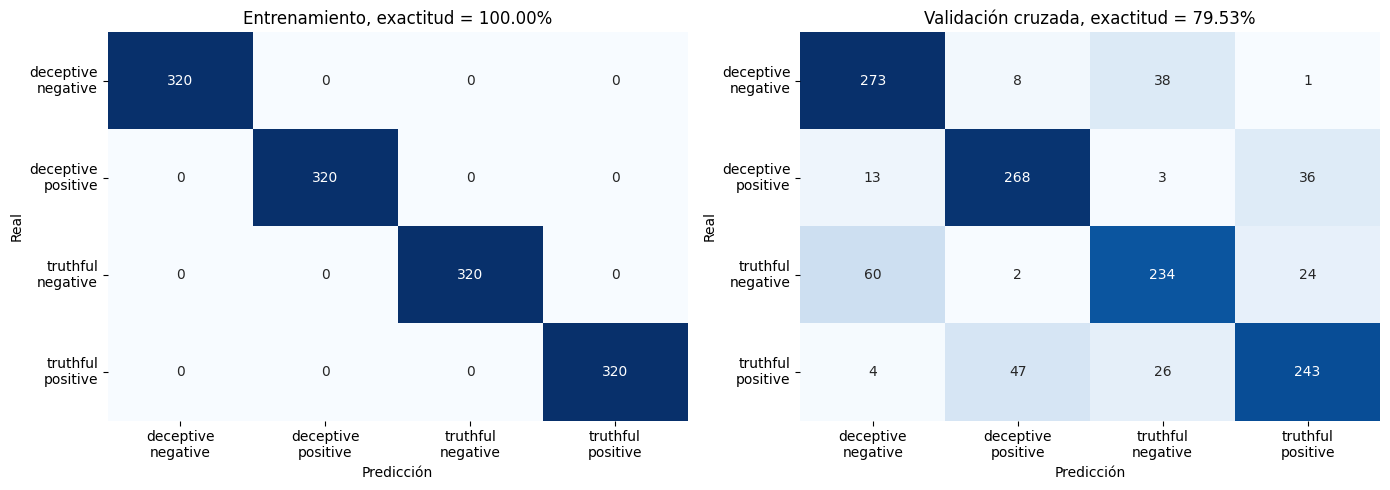

In [74]:
clasificador_multiclase = crear_pipeline(C=np.inf).fit(X_train, y_train_mc)
evaluacion_cv(clasificador_multiclase, X_train, y_train_mc, cv, graph_size=(14, 5))

In [75]:
%%time

grid_search_mc = GridSearchCV(estimator=crear_pipeline(C=1.0),
                              param_grid={'modelo__C': 1/lambdas},
                              cv=cv,          # StratifiedKFold estratifica por las 4 clases
                              return_train_score=True,
                              n_jobs=-1,
                              verbose=1
                              ).fit(X_train, y_train_mc)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
CPU times: user 836 ms, sys: 64.2 ms, total: 900 ms
Wall time: 54.2 s


In [76]:
cv_results_mc = pd.DataFrame(grid_search_mc.cv_results_)
cv_results_mc['lambda'] = 1 / cv_results_mc['param_modelo__C']
cv_results_mc[['lambda', 'param_modelo__C', 'mean_train_score', 'mean_test_score',
               'std_test_score', 'rank_test_score']].sort_values('rank_test_score')

,lambda,param_modelo__C,mean_train_score,mean_test_score,std_test_score,rank_test_score
11,0.562341,1.778279,0.993750,0.817187,0.014278,1
10,0.316228,3.162278,0.998437,0.814844,0.009111,2
12,1.000000,1.000000,0.985156,0.814063,0.012742,3
13,1.778279,0.562341,0.973047,0.812500,0.008558,4
9,0.177828,5.623413,0.999219,0.810937,0.008414,5
7,0.056234,17.782794,1.000000,0.807031,0.013441,6
8,0.100000,10.000000,1.000000,0.807031,0.013212,6
14,3.162278,0.316228,0.957031,0.804688,0.013304,8
6,0.031623,31.622777,1.000000,0.803125,0.014741,9
5,0.017783,56.234133,1.000000,0.802344,0.013212,10


In [77]:
C_best_mc = grid_search_mc.best_params_['modelo__C']
C_best_mc

np.float64(1.7782794100389228)

In [78]:
clasificador_multiclase_ridge = crear_pipeline(C=C_best_mc).fit(X_train, y_train_mc)

print("Exactitud en el conjunto de entrenamiento: {:.4f}".format(
    clasificador_multiclase_ridge.score(X_train, y_train_mc)))
print("Exactitud con validación cruzada:           {:.4f}".format(grid_search_mc.best_score_))
clasificador_multiclase_ridge

Exactitud en el conjunto de entrenamiento: 0.9930
Exactitud con validación cruzada:           0.8172


Pipeline(steps=[('tfidf', TfidfVectorizer(min_df=2)),
                ('modelo',
                 LogisticRegression(C=np.float64(1.7782794100389228),
                                    max_iter=1500, random_state=4,
                                    solver='sag'))])

## Evaluación final en el conjunto de prueba
Es la **única vez** que usamos el conjunto de prueba para la clasificación multiclase.

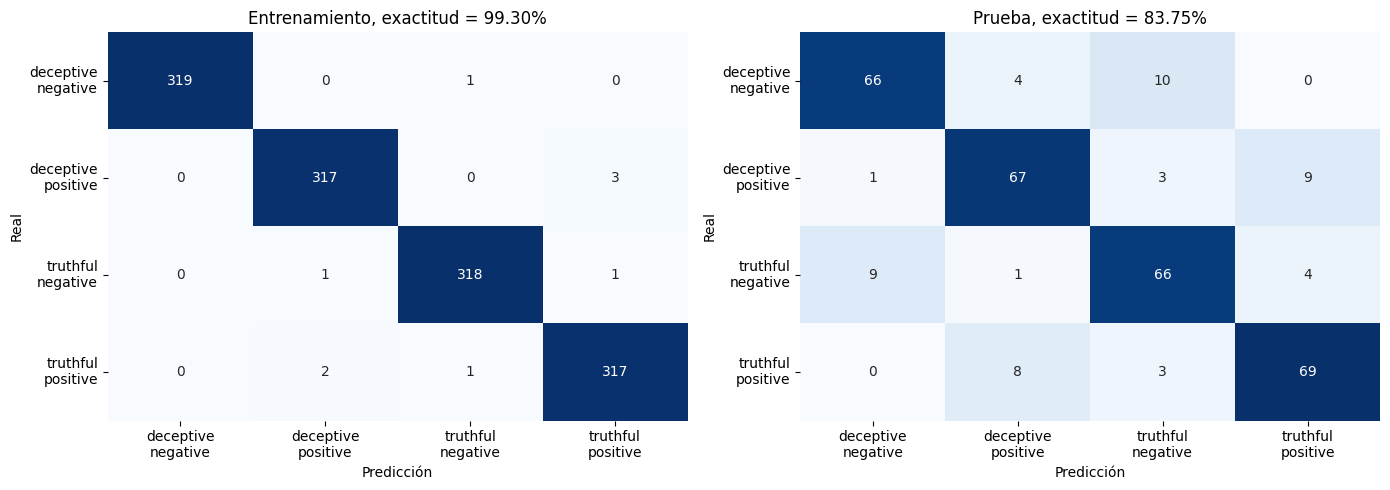

In [79]:
evaluacion_final(clasificador_multiclase_ridge, X_train, y_train_mc, X_test, y_test_mc, graph_size=(14, 5))

In [80]:
clasificador_multiclase_ridge.classes_

array(['deceptive-negative', 'deceptive-positive', 'truthful-negative',
       'truthful-positive'], dtype=object)

In [81]:
clasificador_multiclase_ridge.predict(X_test)[:10]

array(['truthful-negative', 'deceptive-positive', 'truthful-positive',
       'truthful-positive', 'truthful-negative', 'truthful-positive',
       'deceptive-positive', 'deceptive-negative', 'truthful-positive',
       'deceptive-negative'], dtype=object)

In [82]:
clasificador_multiclase_ridge.predict_proba(X_test)[:10].round(3)

array([[0.327, 0.083, 0.524, 0.065],
       [0.16 , 0.795, 0.022, 0.023],
       [0.028, 0.222, 0.051, 0.699],
       [0.022, 0.053, 0.152, 0.773],
       [0.079, 0.044, 0.535, 0.342],
       [0.118, 0.211, 0.142, 0.529],
       [0.034, 0.832, 0.026, 0.109],
       [0.674, 0.012, 0.286, 0.028],
       [0.022, 0.13 , 0.057, 0.791],
       [0.576, 0.004, 0.413, 0.007]])

In [83]:
# Un renglón de coeficientes por clase y una columna por palabra
clasificador_multiclase_ridge['modelo'].coef_.shape

(4, 3281)

In [84]:
clasificador_multiclase_ridge['modelo'].coef_

array([[ 0.04278135,  0.00875928, -0.17913594, ..., -0.07712387,
        -0.17704426, -0.07181551],
       [ 0.07595351,  0.01534385,  0.39514493, ...,  0.03008191,
        -0.05448297,  0.09144658],
       [-0.19922937, -0.18041368, -0.5495015 , ..., -0.10580262,
         0.21197997,  0.06217208],
       [ 0.08049451,  0.15631055,  0.33349251, ...,  0.15284458,
         0.01954726, -0.08180314]], shape=(4, 3281))

# Recursos

Para profundizar en grid_search_cv

https://github.com/codebasics/py/blob/master/ML/15_gridsearch/15_grid_search.ipynb

Validación cruzada en scikit-learn: https://scikit-learn.org/stable/modules/cross_validation.html

Búsqueda de hiperparámetros: https://scikit-learn.org/stable/modules/grid_search.html

Trabajar con texto (Pipeline con vectorizador y clasificador): https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html

Origen de los datos: Ott, M., Choi, Y., Cardie, C. y Hancock, J. T. «Finding Deceptive Opinion Spam by Any Stretch of the Imagination». *Proceedings of ACL*, 2011.